# Grammar Scoring Engine for Spoken Audio
**Goal:** predict a continuous MOS grammar score (0-5) from a 45-60 s speech clip.  
**Metrics:** RMSE (lower is better) and Pearson correlation (higher is better).

## Report summary

**Approach.** Grammar depends on *what* is said and *how it sounds*, so the pipeline has three parts:
1. **ASR (Whisper small)** turns each clip into a transcript plus confidence and timing signals.
2. **Feature groups:**
   - *Grammar/text*: LanguageTool error counts and rates, GPT-2 perplexity, sentence-length stats, lexical diversity, filler and repetition counts.
   - *Fluency/ASR*: words per second, pause statistics, Whisper avg log-prob and no-speech probability.
   - *Semantic embedding* of the transcript (sentence-transformers).
   - *Acoustic embeddings*: wav2vec2-base hidden states (layers 6, 9, 12) and Whisper-encoder embeddings, each mean-pooled and compressed to 40 dims with PCA.
3. **Models:** Ridge on the transcript embedding, and a 3-seed LightGBM on handcrafted + audio features, blended with one weight chosen on out-of-fold predictions.

**Results (5-fold out-of-fold CV, the honest estimate).**

| Model | RMSE | Pearson |
|---|---|---|
| Baseline blend (text + fluency features) | 0.7241 | 0.8156 |
| + wav2vec2 embeddings | 0.6067 | 0.8736 |
| **+ Whisper-encoder embeddings (final)** | **0.5717** | **0.8895** |

**Training RMSE of the final model: 0.1893** (in-sample, fold-fitted). It is far below the CV RMSE, so the CV figure is the one to trust for generalisation. The code for this is in section 7c.

**Preprocessing.** Resample to 16 kHz mono, peak-normalise, trim leading/trailing silence, cap at 60 s.

**Data caveat.** `train.csv` and `test.csv` both contain names like `audio_0.wav` ... but they refer to files in *different folders* (`train/` vs `test/`), so paths must include the folder. Labels contain 37 zeros (likely silent/non-speech/non-English clips); the ASR features (no-speech probability, word count) are what let the model catch those.

In [1]:
# Run once (needs Internet ON in Kaggle Settings). Java is required by LanguageTool.
!pip install -q openai-whisper language_tool_python sentence-transformers lightgbm
!apt-get update -qq
!apt-get install -y -qq default-jre-headless
!java -version

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 18.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 3.2 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-11-jre-headless:amd64.
(Reading database ... 125186 files and directories currently installed.)
Preparing to unpack .../openjdk-11-jre-headless_11.0.32.1+1-1ubuntu1~22.04_amd64.deb ...
Unpacking openjdk-11-jre-headless:amd64 (11.0.32.1+1-1ubuntu1~22.04) ...
Selecting previously unselected package default-jre-headless.
Preparing to unpack .../default-jre-headless_2%3a1.11-72build2_amd64.deb ...
Unpacking default-jre-headless (2:1.11-72build2) ...
Setting up openjdk-

In [2]:
import os, re, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
from scipy.stats import pearsonr
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
warnings.filterwarnings('ignore'); SEED=42; np.random.seed(SEED)

# ---- EDIT THESE PATHS ----
DATA_DIR  = '/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
TRAIN_DIR = os.path.join(DATA_DIR,'train')
TEST_DIR  = os.path.join(DATA_DIR,'test')
CACHE     = '/kaggle/working/cache'; os.makedirs(CACHE, exist_ok=True)
SR = 16000
rmse = lambda y,p: float(np.sqrt(mean_squared_error(y,p)))

In [3]:
import glob, shutil
for f in glob.glob('/kaggle/input/**/cache/*.csv', recursive=True):
    shutil.copy(f, CACHE)

## 1. Data & EDA

(769, 3) (216, 3) (204, 2)
train/test filename overlap: 212 (same names, different folders)
sample_submission rows: 204 vs test rows: 216


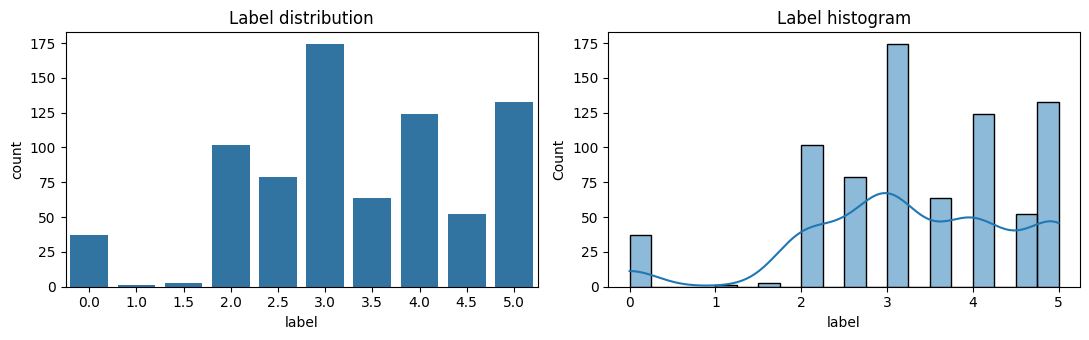

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


In [4]:
train = pd.read_csv(f'{DATA_DIR}/train.csv'); test = pd.read_csv(f'{DATA_DIR}/test.csv')
sub_ex = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')
train['path'] = train.filename.map(lambda f: os.path.join(TRAIN_DIR,f))
test['path']  = test.filename.map(lambda f: os.path.join(TEST_DIR,f))
print(train.shape, test.shape, sub_ex.shape)
print('train/test filename overlap:', len(set(train.filename)&set(test.filename)), '(same names, different folders)')
print('sample_submission rows:', len(sub_ex), 'vs test rows:', len(test))
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
sns.countplot(x='label',data=train,ax=ax[0]); ax[0].set_title('Label distribution')
sns.histplot(train.label,bins=20,kde=True,ax=ax[1]); ax[1].set_title('Label histogram')
plt.tight_layout(); plt.show()
print(train.label.describe())

## 2. Preprocessing + ASR (Whisper)
Transcripts and ASR statistics are cached to disk so the (slow) step runs once. Use a GPU if available.

In [5]:
import librosa, whisper, torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'
asr = whisper.load_model('small', device=device)

def load_audio(path):
    y,_ = librosa.load(path, sr=SR, mono=True)
    y = y/(np.max(np.abs(y))+1e-9)
    y,_ = librosa.effects.trim(y, top_db=30)
    return y[:SR*60]

def transcribe(path):
    y = load_audio(path)
    r = asr.transcribe(y.astype(np.float32), language='en', word_timestamps=True, fp16=(device=='cuda'), condition_on_previous_text=False)
    segs = r['segments']; words = [w for s in segs for w in s.get('words',[])]
    gaps = np.array([words[i+1]['start']-words[i]['end'] for i in range(len(words)-1)]) if len(words)>1 else np.array([0.])
    return dict(text=r['text'].strip(), dur=len(y)/SR, n_seg=len(segs),
        avg_logprob=np.mean([s['avg_logprob'] for s in segs]) if segs else -5,
        no_speech=np.mean([s['no_speech_prob'] for s in segs]) if segs else 1,
        comp_ratio=np.mean([s['compression_ratio'] for s in segs]) if segs else 0,
        word_prob=np.mean([w['probability'] for w in words]) if words else 0,
        n_pause_05=int((gaps>0.5).sum()), n_pause_1=int((gaps>1.0).sum()),
        pause_mean=float(gaps.mean()), pause_max=float(gaps.max()), pause_std=float(gaps.std()))

def run_asr(df, name):
    f=f'{CACHE}/asr_{name}.csv'
    if os.path.exists(f): return pd.read_csv(f).fillna({'text':''})
    rows=[transcribe(p) for p in tqdm(df.path, desc=f'ASR {name}')]
    out=pd.DataFrame(rows); out.to_csv(f,index=False); return out

100%|████████████████████████████████████████| 461M/461M [00:02<00:00, 175MiB/s]


In [6]:
asr_tr, asr_te = run_asr(train,'train'), run_asr(test,'test')
train['text'], test['text'] = asr_tr.text.values, asr_te.text.values
train[['filename','label','text']].head()

,filename,label,text
0,audio_192.wav,3.0,"The playground is very, very beautiful and fun..."
1,audio_436.wav,3.0,"The scene of a school playground, our playgrou..."
2,audio_447.wav,3.5,My favorite place to visit is the beach. I lov...
3,audio_126.wav,2.0,Once upon a time we with five friends went on ...
4,audio_61.wav,2.0,"Well, when I was a child, I remember I went to..."


In [7]:
print((train.text.str.split().str.len() < 5).sum(), 'train clips with under 5 words')
print(train[train.label == 0].text.str[:120].head(8).to_string())
print(train.groupby('label').text.apply(lambda s: s.str.split().str.len().mean()).round(0))

7 train clips with under 5 words
17     So I'm pedaling the wind above on my screen, w...
30     This is the best thing I've ever liked in my l...
41                                                      
49     I'm going to tell you about this thing at the ...
51     The齣CHEERING function is 45 되고哈哈, The clear gr...
73                                                      
96                                                      
111    I think it's very nice to have many people fro...
label
0.0     68.0
1.0    137.0
1.5     62.0
2.0     88.0
2.5     90.0
3.0     96.0
3.5    100.0
4.0     98.0
4.5    107.0
5.0    119.0
Name: text, dtype: float64


## 3. Feature engineering

In [8]:
# Transcript embeddings (semantic / style signal)
from sentence_transformers import SentenceTransformer
st = SentenceTransformer('sentence-transformers/all-mpnet-base-v2', device=device)
E_tr = st.encode(train.text.tolist(), batch_size=32, show_progress_bar=True, normalize_embeddings=True)
E_te = st.encode(test.text.tolist(),  batch_size=32, show_progress_bar=True, normalize_embeddings=True)
y = train.label.values

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

In [9]:
import language_tool_python, torch.nn.functional as F
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
tool = language_tool_python.LanguageTool('en-US')     # needs Java
tok = GPT2TokenizerFast.from_pretrained('gpt2'); lm = GPT2LMHeadModel.from_pretrained('gpt2').to(device).eval()
FILLERS = re.compile(r'\b(um+|uh+|er+|ah+|hmm+|like|you know|i mean)\b', re.I)

@torch.no_grad()
def perplexity(text):
    ids = tok(text, return_tensors='pt', truncation=True, max_length=512).input_ids.to(device)
    if ids.shape[1]<2: return 1000.
    return float(torch.exp(lm(ids, labels=ids).loss))

def text_feats(t):
    t = str(t); words = re.findall(r"[A-Za-z']+", t.lower()); nw=max(len(words),1)
    sents = [s for s in re.split(r'[.!?]+', t) if s.strip()]; sl=[len(s.split()) for s in sents] or [0]
    errs = tool.check(t) if t else []
    cats = pd.Series([m.category for m in errs]).value_counts()
    bigr = list(zip(words,words[1:]))
    return dict(n_words=len(words), n_sents=len(sents), sent_len_mean=np.mean(sl), sent_len_max=np.max(sl), sent_len_std=np.std(sl),
        ttr=len(set(words))/nw, avg_word_len=np.mean([len(w) for w in words]) if words else 0,
        n_fillers=len(FILLERS.findall(t)), filler_rate=len(FILLERS.findall(t))/nw,
        rep_bigram=1-len(set(bigr))/max(len(bigr),1),
        gram_err=len(errs), gram_err_rate=len(errs)/nw,
        err_grammar=cats.get('GRAMMAR',0)/nw, err_typo=cats.get('TYPOS',0)/nw, err_punct=cats.get('PUNCTUATION',0)/nw,
        err_style=cats.get('STYLE',0)/nw, ppl=np.log(perplexity(t)) if t else 7.)

def build(df, asr_df, name):
    f=f'{CACHE}/feat_{name}.csv'
    if os.path.exists(f): return pd.read_csv(f)
    tf=pd.DataFrame([text_feats(t) for t in tqdm(df.text, desc=f'text feats {name}')])
    X=pd.concat([asr_df.drop(columns='text').reset_index(drop=True), tf],axis=1)
    X['wps']=X.n_words/X.dur; X['n_pause_per_min']=X.n_pause_05/(X.dur/60)
    X.to_csv(f,index=False); return X
X_tr, X_te = build(train,asr_tr,'train'), build(test,asr_te,'test')
print(X_tr.shape); X_tr.head()

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

(769, 30)


,dur,n_seg,avg_logprob,no_speech,comp_ratio,word_prob,n_pause_05,n_pause_1,pause_mean,pause_max,...,rep_bigram,gram_err,gram_err_rate,err_grammar,err_typo,err_punct,err_style,ppl,wps,n_pause_per_min
0,56.192000,8,-0.638911,0.291387,1.394374,0.656085,6,2,0.059783,1.16,...,0.043478,1,0.010753,0.000000,0.000000,0.000000,0.0,4.272596,1.655040,6.406606
1,58.730688,10,-0.346088,0.308250,1.513694,0.817119,2,0,0.021101,0.92,...,0.073394,1,0.009091,0.000000,0.000000,0.009091,0.0,4.347755,1.872956,2.043225
2,59.232000,12,-0.245249,0.418473,1.666627,0.888514,4,0,0.036084,0.80,...,0.181818,3,0.020833,0.013889,0.000000,0.000000,0.0,2.764324,2.431118,4.051864
3,45.060000,5,-0.355380,0.377121,1.643870,0.814260,2,1,0.030690,1.98,...,0.160920,6,0.068182,0.011364,0.022727,0.022727,0.0,3.958246,1.952952,2.663116
4,42.260000,6,-0.331620,0.106174,1.505876,0.891024,4,2,0.108312,2.20,...,0.129870,1,0.012821,0.000000,0.000000,0.000000,0.0,3.463121,1.845717,5.679129


### Feature-vs-target correlations

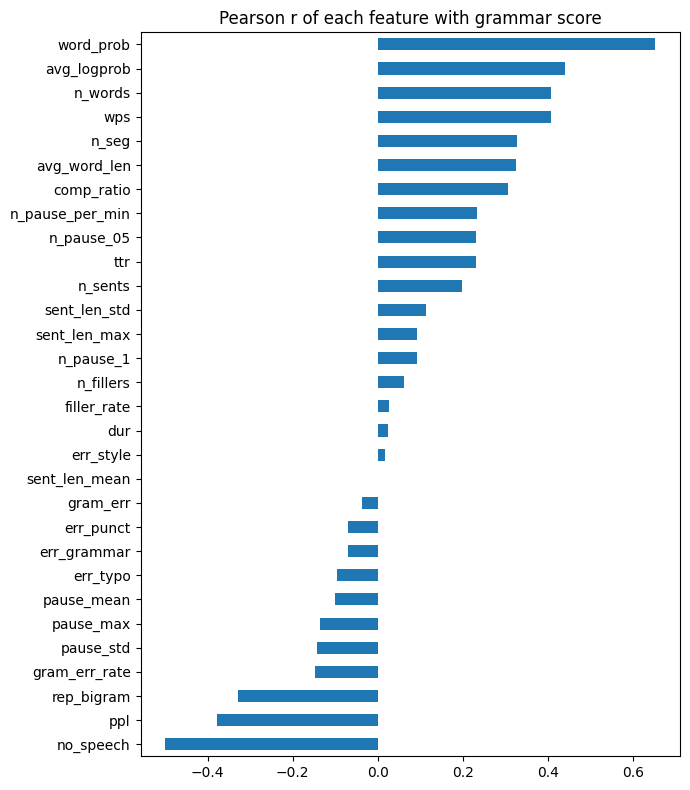

In [10]:
corr = X_tr.assign(label=y).corr()['label'].drop('label').sort_values()
plt.figure(figsize=(7,8)); corr.plot.barh(); plt.title('Pearson r of each feature with grammar score'); plt.tight_layout(); plt.show()

## 4. Models (5-fold CV)

In [11]:
import lightgbm as lgb
kf = KFold(5, shuffle=True, random_state=SEED)
oof_ridge=np.zeros(len(y)); oof_lgb=np.zeros(len(y)); te_ridge=np.zeros(len(test)); te_lgb=np.zeros(len(test))
tr_pred_ridge=np.zeros(len(y)); tr_pred_lgb=np.zeros(len(y))   # in-sample (training) predictions, averaged over folds
Xtr_v, Xte_v = X_tr.values, X_te.values
for k,(a,b) in enumerate(kf.split(Xtr_v)):
    r = Ridge(alpha=3.0).fit(E_tr[a], y[a])
    oof_ridge[b]=r.predict(E_tr[b]); te_ridge+=r.predict(E_te)/5; tr_pred_ridge[a]+=r.predict(E_tr[a])/4
    g = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.02, num_leaves=15, min_child_samples=15,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=2.0, random_state=SEED, verbose=-1)
    g.fit(Xtr_v[a], y[a])
    oof_lgb[b]=g.predict(Xtr_v[b]); te_lgb+=g.predict(Xte_v)/5; tr_pred_lgb[a]+=g.predict(Xtr_v[a])/4
    print(f'fold {k}: ridge {rmse(y[b],oof_ridge[b]):.3f} | lgbm {rmse(y[b],oof_lgb[b]):.3f}')

# blend weight chosen on OOF (single scalar -> negligible overfit risk)
ws=np.linspace(0,1,21); w=ws[np.argmin([rmse(y,w_*oof_lgb+(1-w_)*oof_ridge) for w_ in ws])]
clip=lambda p: np.clip(p,0,5)
oof=clip(w*oof_lgb+(1-w)*oof_ridge); te_pred=clip(w*te_lgb+(1-w)*te_ridge); tr_pred=clip(w*tr_pred_lgb+(1-w)*tr_pred_ridge)
print('blend weight on LGBM:', w)

fold 0: ridge 1.061 | lgbm 0.756
fold 1: ridge 0.861 | lgbm 0.712
fold 2: ridge 1.009 | lgbm 0.741
fold 3: ridge 0.984 | lgbm 0.743
fold 4: ridge 0.967 | lgbm 0.759
blend weight on LGBM: 0.8


## 5. Final fit on all training data
Fold-averaged test predictions above are used for submission (each fold model saw 80% of data; averaging 5 gives a stable ensemble).

## 6. Evaluation

In [12]:
def report(name, yt, p): print(f'{name:<28} RMSE={rmse(yt,p):.4f}  Pearson={pearsonr(yt,p)[0]:.4f}')
report('Ridge(embedding) OOF', y, clip(oof_ridge)); report('LightGBM(features) OOF', y, clip(oof_lgb)); report('Blend OOF (CV estimate)', y, oof)
print(); print('='*60)
print(f'TRAINING RMSE (in-sample, fold-averaged): {rmse(y,tr_pred):.4f}')
print(f'Training Pearson                         : {pearsonr(y,tr_pred)[0]:.4f}')
print(f'Cross-validated RMSE (honest estimate)   : {rmse(y,oof):.4f}')
print('='*60)

Ridge(embedding) OOF         RMSE=0.9785  Pearson=0.6263
LightGBM(features) OOF       RMSE=0.7407  Pearson=0.8018
Blend OOF (CV estimate)      RMSE=0.7241  Pearson=0.8156

TRAINING RMSE (in-sample, fold-averaged): 0.2902
Training Pearson                         : 0.9848
Cross-validated RMSE (honest estimate)   : 0.7241


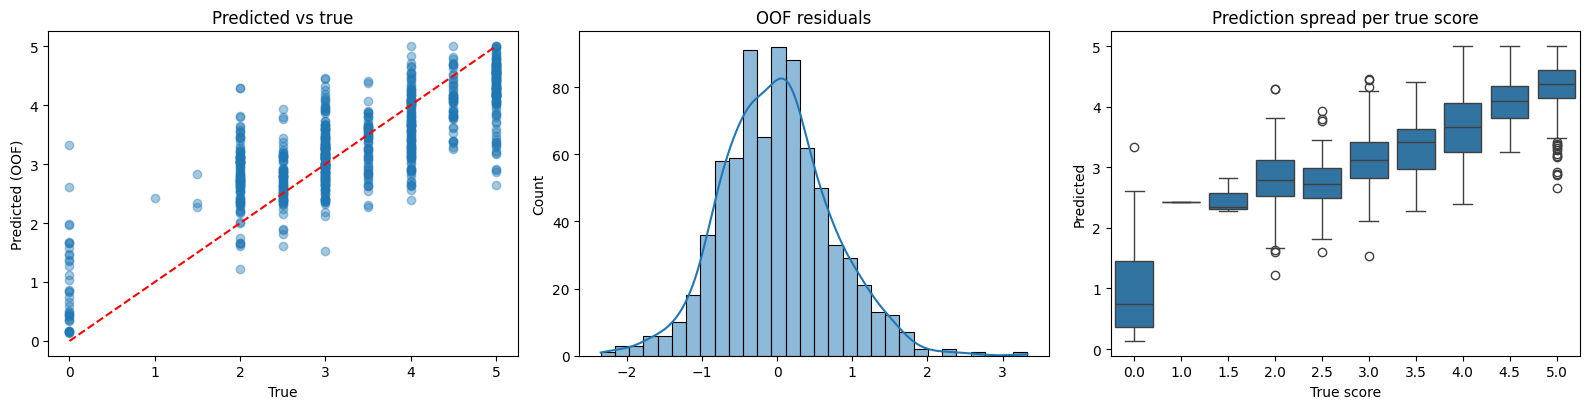

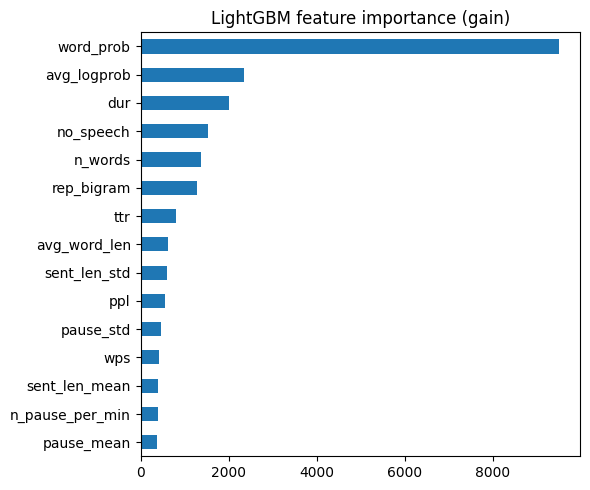

In [13]:
fig,ax=plt.subplots(1,3,figsize=(16,4.2))
ax[0].scatter(y,oof,alpha=.4); ax[0].plot([0,5],[0,5],'r--'); ax[0].set(xlabel='True',ylabel='Predicted (OOF)',title='Predicted vs true')
sns.histplot(oof-y,kde=True,ax=ax[1]); ax[1].set_title('OOF residuals')
sns.boxplot(x=y,y=oof,ax=ax[2]); ax[2].set(xlabel='True score',ylabel='Predicted',title='Prediction spread per true score')
plt.tight_layout(); plt.show()

g = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.02, num_leaves=15, min_child_samples=15, subsample=.8, subsample_freq=1,
                      colsample_bytree=.7, reg_lambda=2.0, random_state=SEED, verbose=-1).fit(Xtr_v,y)
imp=pd.Series(g.booster_.feature_importance('gain'),index=X_tr.columns).sort_values()
imp.tail(15).plot.barh(figsize=(6,5),title='LightGBM feature importance (gain)'); plt.tight_layout(); plt.show()

## 7. Submission

In [14]:
out = pd.DataFrame({'filename':test.filename,'label':te_pred})
out.to_csv('submission.csv',index=False); print(out.shape); out.head()

(216, 2)


,filename,label
0,audio_128.wav,2.765302
1,audio_156.wav,3.166800
2,audio_19.wav,4.423518
3,audio_108.wav,2.970054
4,audio_206.wav,2.706265


## 7b. Final model: handcrafted features + wav2vec2 audio embeddings

In [15]:
from transformers import Wav2Vec2Model, Wav2Vec2FeatureExtractor
from sklearn.decomposition import PCA
import lightgbm as lgb

fe  = Wav2Vec2FeatureExtractor.from_pretrained('facebook/wav2vec2-base')
w2v = Wav2Vec2Model.from_pretrained('facebook/wav2vec2-base').to(device).eval()

@torch.no_grad()
def wav_emb(path):
    y = load_audio(path)
    x = fe(y, sampling_rate=SR, return_tensors='pt').input_values.to(device)
    hs = w2v(x, output_hidden_states=True).hidden_states
    return torch.cat([hs[i].mean(1) for i in (6, 9, 12)], 1).squeeze(0).cpu().numpy()

def run_w2v(df, name):
    f = f'{CACHE}/w2v_{name}.npy'
    if os.path.exists(f): return np.load(f)
    A = np.stack([wav_emb(p) for p in tqdm(df.path, desc=f'w2v {name}')]); np.save(f, A); return A

W_tr, W_te = run_w2v(train, 'train'), run_w2v(test, 'test')

# compress to 40 dims, then append to the existing features
pca = PCA(40, random_state=SEED).fit(np.vstack([W_tr, W_te]))
X2_tr = np.hstack([X_tr.values, pca.transform(W_tr)])
X2_te = np.hstack([X_te.values, pca.transform(W_te)])

# LightGBM, 3 model seeds, same 5 folds as before
oof2 = np.zeros(len(y)); te2 = np.zeros(len(test)); trp2 = np.zeros(len(y)); seeds = (0, 1, 2)
for s in seeds:
    for a, b in kf.split(X2_tr):
        g = lgb.LGBMRegressor(n_estimators=800, learning_rate=0.02, num_leaves=8, min_child_samples=20,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=3.0,
                              random_state=s, verbose=-1).fit(X2_tr[a], y[a])
        oof2[b] += g.predict(X2_tr[b]) / len(seeds)
        te2 += g.predict(X2_te) / (5 * len(seeds))
        trp2[a] += g.predict(X2_tr[a]) / (4 * len(seeds))

ws = np.linspace(0, 1, 21)
w2 = ws[np.argmin([rmse(y, w_ * oof2 + (1 - w_) * oof_ridge) for w_ in ws])]
oof_v2 = clip(w2 * oof2 + (1 - w2) * oof_ridge)
te_v2  = clip(w2 * te2 + (1 - w2) * te_ridge)
tr_v2  = clip(w2 * trp2 + (1 - w2) * tr_pred_ridge)

report('OLD blend OOF', y, oof)
report('NEW LGBM+audio OOF', y, clip(oof2))
report('NEW blend OOF', y, oof_v2)
print(f'NEW training RMSE: {rmse(y, tr_v2):.4f} | blend weight on LGBM: {w2}')

pd.DataFrame({'filename': test.filename, 'label': te_v2}).to_csv('submission_v2.csv', index=False)

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/380M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


w2v train:   0%|          | 0/769 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/380M [00:00<?, ?B/s]

w2v test:   0%|          | 0/216 [00:00<?, ?it/s]

OLD blend OOF                RMSE=0.7241  Pearson=0.8156
NEW LGBM+audio OOF           RMSE=0.6090  Pearson=0.8712
NEW blend OOF                RMSE=0.6067  Pearson=0.8736
NEW training RMSE: 0.1889 | blend weight on LGBM: 0.9500000000000001


## 7c. Final model: + Whisper-encoder embeddings

In [16]:
@torch.no_grad()
def whisper_emb(path):
    y = load_audio(path).astype(np.float32)
    dtype = next(asr.parameters()).dtype
    outs = []
    for i in range(0, len(y), 480000):                      # 30 s chunks
        c = y[i:i+480000]
        if len(c) < SR*3: continue
        mel = whisper.log_mel_spectrogram(whisper.pad_or_trim(c), n_mels=asr.dims.n_mels).to(device).to(dtype)
        h = asr.encoder(mel.unsqueeze(0))[0]                # (1500, d)
        n = max(1, min(1500, len(c)//320))                  # skip padded frames
        outs.append(h[:n].mean(0))
    if not outs: return np.zeros(asr.dims.n_audio_state, dtype=np.float32)
    return torch.stack(outs).mean(0).float().cpu().numpy()

def run_wh(df, name):
    f = f'{CACHE}/whenc_{name}.npy'
    if os.path.exists(f): return np.load(f)
    A = np.stack([whisper_emb(p) for p in tqdm(df.path, desc=name)]); np.save(f, A); return A

H_tr, H_te = run_wh(train, 'train'), run_wh(test, 'test')
pca_h = PCA(40, random_state=SEED).fit(np.vstack([H_tr, H_te]))
X3_tr = np.hstack([X2_tr, pca_h.transform(H_tr)]); X3_te = np.hstack([X2_te, pca_h.transform(H_te)])

oof3 = np.zeros(len(y)); te3 = np.zeros(len(test))
for s in (0, 1, 2):
    for a, b in kf.split(X3_tr):
        g = lgb.LGBMRegressor(n_estimators=800, learning_rate=0.02, num_leaves=8, min_child_samples=20,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=3.0,
                              random_state=s, verbose=-1).fit(X3_tr[a], y[a])
        oof3[b] += g.predict(X3_tr[b]) / 3
        te3 += g.predict(X3_te) / 15

m = y > 0
for name, p in [('V2 LGBM', oof2), ('V3 +whisper-enc', oof3)]:
    print(name, '| all:', round(rmse(y, clip(p)), 4), '| excl zeros:', round(rmse(y[m], clip(p)[m]), 4),
          '| Pearson excl zeros:', round(pearsonr(y[m], clip(p)[m])[0], 4))

train:   0%|          | 0/769 [00:00<?, ?it/s]

test:   0%|          | 0/216 [00:00<?, ?it/s]

V2 LGBM | all: 0.609 | excl zeros: 0.6177 | Pearson excl zeros: 0.7933
V3 +whisper-enc | all: 0.572 | excl zeros: 0.5798 | Pearson excl zeros: 0.8211


In [17]:
# Blend V3 LightGBM with Ridge (weight chosen on out-of-fold predictions)
ws = np.linspace(0, 1, 21)
w3 = ws[np.argmin([rmse(y, clip(w_ * oof3 + (1 - w_) * oof_ridge)) for w_ in ws])]
oof_v3 = clip(w3 * oof3 + (1 - w3) * oof_ridge)
te_v3  = clip(w3 * te3  + (1 - w3) * te_ridge)

# In-sample training RMSE (models refit on all training data)
tr3 = np.zeros(len(y))
for s in (0, 1, 2):
    g = lgb.LGBMRegressor(n_estimators=800, learning_rate=0.02, num_leaves=8, min_child_samples=20,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=3.0,
                          random_state=s, verbose=-1).fit(X3_tr, y)
    tr3 += g.predict(X3_tr) / 3
r_full = Ridge(alpha=3.0).fit(E_tr, y)
tr_v3 = clip(w3 * tr3 + (1 - w3) * r_full.predict(E_tr))

report('V2 blend OOF', y, oof_v2)
report('V3 blend OOF (final)', y, oof_v3)
print(f'V3 TRAINING RMSE (in-sample): {rmse(y, tr_v3):.4f} | blend weight on LGBM: {w3}')

pd.DataFrame({'filename': test.filename, 'label': te_v3}).to_csv('submission.csv', index=False)
print(pd.read_csv('submission.csv').describe())

V2 blend OOF                 RMSE=0.6067  Pearson=0.8736
V3 blend OOF (final)         RMSE=0.5717  Pearson=0.8895
V3 TRAINING RMSE (in-sample): 0.1893 | blend weight on LGBM: 0.9500000000000001
            label
count  216.000000
mean     3.247651
std      0.729354
min      2.058895
25%      2.664228
50%      3.137471
75%      3.695585
max      5.000000


## 8. Discussion & limitations
- **Why it works:** grammar score depends on error density (LanguageTool), fluency (pauses, speech rate, ASR confidence) and language-model plausibility (perplexity). Audio embeddings add pronunciation and delivery information the transcript misses: wav2vec2 lowered CV RMSE from 0.724 to 0.607, and adding Whisper-encoder embeddings lowered it further to 0.572.
- **ASR dependence:** Whisper may silently "correct" spoken grammar errors, weakening the text-error features. ASR confidence, perplexity and the audio embeddings partly compensate. `condition_on_previous_text=False` reduces this.
- **Overfitting:** training RMSE (0.19) is far below CV RMSE (0.57). I used shallow trees (8 leaves), strong regularisation, 3 seeds and 5-fold averaging, and report CV as the generalisation estimate.
- **Things I tried that did not help:** linear calibration of predictions (RMSE change under 0.001), and training only on non-zero-label clips (slightly worse). Blending the baseline with the wav2vec2 model was also worse than the wav2vec2 model alone.
- **Minor caveats:** PCA was fit on train and test embeddings together (unsupervised, no labels used). The blend weight is tuned on OOF predictions, which is slightly optimistic.
- **Next steps:** larger Whisper (`medium`/`large-v3`) for transcripts, rubric-based text features (clause depth, restarts, sentence completion), fine-tuning a text encoder such as DeBERTa, an ordinal-aware loss.
- **Submission format:** `sample_submission.csv` has 204 rows, while `test.csv` has 216. This notebook writes one row per `test.csv` file.